# Obtención de datos OSM por comuna

Descarga desde OpenStreetMap los equipamientos (salud, educación, transporte, etc.) de **varias comunas** y construye un dataset con **una fila por comuna**, listo para unirlo con el ICVU y entrenar el modelo.

v1.0 · 18-10-2026

**Cambios respecto de `data_obtain_test.ipynb`**

| Problema | Corrección |
|---|---|
| Solo una comuna (1 fila de ICVU) | Ciclo sobre `COMUNAS`, con caché por comuna (si se corta, se retoma donde quedó) |
| Paraderos contados 2 veces (`Paradero_bus` + `Paradero_plataforma`) y estaciones 2 veces (`Metro_estacion` + `Metro_railway`) | Cada objeto OSM se cuenta **una sola vez por categoría** (gana el primer tipo de la lista) |
| `Metro_railway` incluía el funicular | Renombrado a `Tren_estacion`: solo estaciones de tren (EFE, Metrotren), sin funicular ni metro |
| `Centro_salud` = 0 (los CESFAM están etiquetados como clínica/hospital) | Regla por nombre: CESFAM, CECOSF, SAPU, SAR, SUR, COSAM → `Centro_salud` |
| Mismo lugar mapeado como punto y como polígono | Se elimina el duplicado si tiene el mismo nombre y está a < 30 m |
| Parques y zonas contados como "1" sin importar su tamaño | Se calcula el **área** (m²) y el % de la comuna cubierto (`pct_area_*`) |
| Efecto borde (lo que está al otro lado de la calle no cuenta) | Descarga con un margen `BUFFER_M`; columna `dentro_comuna` para distinguir |
| CSV con 220 columnas de etiquetas OSM | Se guardan solo las columnas útiles |
| Conteos sin normalizar | Densidad por km² y, si se entrega población, por 10.000 hab |

> **Nota sobre sesgo:** OSM suele estar más completo en comunas de mayores ingresos, y eso se correlaciona con el ICVU. Hay que mencionarlo como limitación en el informe.

### Librerías
La celda siguiente instala lo necesario en el kernel actual (solo hace falta la primera vez).

In [ ]:
%pip install -q pandas geopandas osmnx matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import re
import time
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

### Parámetros

In [ ]:
DEBUG = True

# --- Comunas a descargar (editar libremente) ---------------------------------
# Las 42 comunas de la Región Metropolitana que mide el ICVU 2025 (CChC / Estudios Urbanos UC),
# con su nivel publicado (solo como referencia; el modelo usa el puntaje numérico).
# Para una prueba rápida: COMUNAS = ["Providencia", "Maipú", "Pudahuel"]
NIVEL_ICVU_2025 = {
    # Alto
    "Las Condes": "Alto", "Vitacura": "Alto", "Providencia": "Alto", "Ñuñoa": "Alto",
    "Lo Barnechea": "Alto", "La Reina": "Alto", "Santiago": "Alto", "San Miguel": "Alto",
    "Huechuraba": "Alto",
    # Medio alto
    "Colina": "Medio alto", "Maipú": "Medio alto", "Peñalolén": "Medio alto",
    "Independencia": "Medio alto", "La Cisterna": "Medio alto", "Recoleta": "Medio alto",
    "Estación Central": "Medio alto",
    # Medio bajo
    "Macul": "Medio bajo", "La Florida": "Medio bajo", "Pudahuel": "Medio bajo",
    "Cerrillos": "Medio bajo", "Quinta Normal": "Medio bajo", "San Joaquín": "Medio bajo",
    "Peñaflor": "Medio bajo", "Quilicura": "Medio bajo", "Puente Alto": "Medio bajo",
    "Lampa": "Medio bajo", "Renca": "Medio bajo", "Buin": "Medio bajo",
    "San Bernardo": "Medio bajo",
    # Bajo
    "Paine": "Bajo", "Conchalí": "Bajo", "Lo Prado": "Bajo", "Padre Hurtado": "Bajo",
    "Pedro Aguirre Cerda": "Bajo", "La Granja": "Bajo", "El Bosque": "Bajo",
    "La Pintana": "Bajo", "Melipilla": "Bajo", "Lo Espejo": "Bajo", "San Ramón": "Bajo",
    "Cerro Navia": "Bajo", "Talagante": "Bajo",
}
COMUNAS = list(NIVEL_ICVU_2025)

# Texto que se agrega al nombre para geocodificar en Nominatim
SUFIJO_CONSULTA = ", Región Metropolitana de Santiago, Chile"
# Consultas especiales cuando el nombre es ambiguo (revisar el mapa de límites más abajo).
# "R<número>" = relación exacta de OpenStreetMap (búsquela en nominatim.openstreetmap.org)
CONSULTA_ESPECIAL = {
    "Santiago": "Santiago, Provincia de Santiago, Región Metropolitana de Santiago, Chile",
    "Talagante": "R1626706",   # por nombre se obtenía la Provincia de Talagante (581 km²)
}
AREA_MAX_KM2 = 1800   # una comuna más grande que esto = se geocodificó otra cosa (región, provincia)

# --- Descarga ------------------------------------------------------------------
BUFFER_M = 500             # margen alrededor de la comuna (efecto borde). 0 = sin margen
CONTAR_CON_BUFFER = True   # True: los conteos incluyen el margen; False: solo dentro de la comuna
MARGEN_DESCARGA_M = 100         # la zona de descarga se amplía y simplifica para que la
TOLERANCIA_SIMPLIFICAR_M = 50   # consulta a Overpass no sea demasiado grande (error 413)
REINTENTOS = 3
# Servidores Overpass: si el principal está saturado se prueba el siguiente
# (se reordena solo: el último que funcionó se prueba primero)
OVERPASS_URLS = [
    "https://maps.mail.ru/osm/tools/overpass/api",   # VK Maps
    "https://overpass-api.de/api",                    # principal (FOSSGIS), suele estar saturado
    "https://overpass.private.coffee/api",
]
ARCHIVO_LOG = "descarga_log.txt"   # registro del avance de la descarga
PAUSA_ENTRE_COMUNAS_S = 5  # cortesía con el servidor Overpass

ox.settings.use_cache = True
ox.settings.requests_timeout = 300

# --- Archivos ------------------------------------------------------------------
CARPETA_CACHE = Path("datos_comunas")        # un .gpkg por comuna (permite retomar)
SALIDA_GPKG = "features_comunas.gpkg"        # todos los puntos + límites
SALIDA_CSV = "features_comunas.csv"          # todos los puntos (sin geometría)
SALIDA_RESUMEN = "resumen_conteos.csv"       # conteos comuna × tipo (formato largo)
SALIDA_DATASET = "dataset_comunas.csv"       # UNA FILA POR COMUNA -> entrada del modelo

ARCHIVO_POBLACION = "poblacion_comunas.csv"  # opcional: columnas comuna,poblacion (Censo 2024)
ARCHIVO_ICVU = "icvu_comunas.csv"            # columnas comuna,nivel_2025,ICVU_nivel. Si no existe, se crea

CRS_GEO = "EPSG:4326"
CRS_METRICO = 32719   # UTM 19S, metros (Santiago)

# --- Categorías y tipos (mismas variables que la versión anterior) --------------
categorias = {
    "Salud": {
        "Hospital":        {"amenity": "hospital"},
        "Clinica":         {"amenity": "clinic"},
        "Centro_salud":    {"healthcare": "centre"},          # + regla por nombre (CESFAM, etc.)
        "Consultorio":     {"amenity": "doctors"},
        "Farmacia":        {"amenity": "pharmacy"},
    },
    "Recreativo_Cultural": {
        "Parque":          {"leisure": "park"},
        "Mall":            {"shop": "mall"},
        "Restaurante":     {"amenity": "restaurant"},
        "Museo":           {"tourism": "museum"},
        "Biblioteca":      {"amenity": "library"},
        "Teatro":          {"amenity": "theatre"},
    },
    "Seguridad": {
        "Bomberos":        {"amenity": "fire_station"},
        "Comisaria":       {"amenity": "police"},
    },
    "Educacion": {
        "Colegio":         {"amenity": "school"},
        "Jardin_infantil": {"amenity": "kindergarten"},
        "Universidad":     {"amenity": "university"},
    },
    "Comercio": {
        "Supermercado":    {"shop": "supermarket"},
        "Banco":           {"amenity": "bank"},
        "Feria":           {"amenity": "marketplace"},
        "Almacen":         {"shop": ["convenience", "general", "greengrocer"]},
    },
    "Transporte": {
        # El ORDEN importa: si un objeto calza con dos tipos de la misma categoría, queda en el primero
        "Metro_estacion":  {"station": "subway"},
        "Tren_estacion":   {"railway": "station"},            # antes Metro_railway; se filtra abajo
        "Metro_entrada":   {"railway": "subway_entrance"},
        "Paradero_bus":    {"highway": "bus_stop"},
        "Paradero_plataforma": {"public_transport": "platform"},  # solo las que NO son paradero_bus
        "Terminal_bus":    {"amenity": "bus_station"},
    },
    "Negativos": {
        "Vertedero":       {"landuse": "landfill"},
        "Planta_residuos": {"amenity": "waste_transfer_station"},
        "Industrial":      {"landuse": "industrial"},
        "Fabrica":         {"man_made": "works"},
        "Botilleria":      {"shop": "alcohol"},
        "Bar_pub":         {"amenity": ["bar", "pub", "nightclub"]},
        "Sitio_eriazo":    {"landuse": ["brownfield", "greenfield"]},
        "Suelo_desnudo":   {"natural": "bare_rock"},
    },
}

# Atención primaria pública: se reasigna a Centro_salud por nombre
REGLA_CENTRO_SALUD = (r"(?i)(?:\bcesfam\b|centro de salud familiar|\bcecosf\b|\bsapu\b|\bcosam\b"
                      r"|^\s*(?:sar|sur)\b)")   # SAR/SUR solo al inicio (evita 'Centro Médico Sur')

# Tipos para los que importa la superficie, no solo el número
TIPOS_AREA = ["Parque", "Industrial", "Vertedero", "Sitio_eriazo", "Suelo_desnudo"]

DIST_DUPLICADO_M = 30  # mismo nombre y tipo a menos de esta distancia = mismo lugar
# Paraderos y accesos de metro comparten nombre legítimamente (uno por cada lado de la calle)
TIPOS_SIN_DEDUP_NOMBRE = ["Metro_estacion", "Tren_estacion", "Metro_entrada", "Paradero_bus",
                          "Paradero_plataforma", "Terminal_bus"]

### Funciones

In [ ]:
def slug(texto):
    # 'Ñuñoa' -> 'nunoa', 'Pedro Aguirre Cerda' -> 'pedro_aguirre_cerda'
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", t.lower()).strip("_")


def unir_tags(categorias):
    tags = {}
    for subtipos in categorias.values():
        for t in subtipos.values():
            for k, v in t.items():
                tags.setdefault(k, set()).update(v if isinstance(v, list) else [v])
    return {k: sorted(v) for k, v in tags.items()}


def log(*partes):
    # Muestra el mensaje y lo agrega a ARCHIVO_LOG (permite seguir el avance sin mirar el notebook)
    msg = " ".join(str(p) for p in partes)
    print(msg)
    with open(ARCHIVO_LOG, "a", encoding="utf-8") as fh:
        fh.write(time.strftime("%Y-%m-%d %H:%M:%S ") + msg + "\n")


def _resumen_error(e):
    # Los errores HTTP de Overpass traen una página HTML entera: basta con la primera línea
    return f"{type(e).__name__}: {str(e).splitlines()[0][:200] if str(e) else ''}"


def con_reintentos(fn, *args, **kwargs):
    for intento in range(1, REINTENTOS + 1):
        try:
            return fn(*args, **kwargs)
        except Exception as e:
            if intento == REINTENTOS:
                raise
            espera = 30 * intento
            log(f"   intento {intento} falló ({_resumen_error(e)}); reintento en {espera}s")
            time.sleep(espera)


def descargar_overpass(zona, tags):
    # Prueba los servidores de OVERPASS_URLS en orden; si uno falla (saturado, caído),
    # pasa al siguiente. Hace hasta REINTENTOS rondas por todos los servidores.
    ultimo_error = None
    for ronda in range(1, REINTENTOS + 1):
        for url in OVERPASS_URLS:
            ox.settings.overpass_url = url
            # el control de cupos (/status) solo existe en el servidor principal
            ox.settings.overpass_rate_limit = "overpass-api.de" in url
            t0 = time.perf_counter()
            try:
                resultado = ox.features_from_polygon(zona, tags=tags)
                # el servidor que funcionó pasa al primer lugar para la próxima comuna
                OVERPASS_URLS.remove(url)
                OVERPASS_URLS.insert(0, url)
                return resultado
            except Exception as e:
                ultimo_error = e
                log(f"   ronda {ronda} · {url} falló tras {time.perf_counter() - t0:.0f}s "
                    f"({_resumen_error(e)})")
        if ronda < REINTENTOS:
            espera = 60 * ronda
            log(f"   todos los servidores fallaron; nueva ronda en {espera}s")
            time.sleep(espera)
    raise ultimo_error


def consulta_de(comuna):
    return CONSULTA_ESPECIAL.get(comuna, comuna + SUFIJO_CONSULTA)


def geocodificar_comuna(comuna):
    consulta = consulta_de(comuna)
    por_id = bool(re.fullmatch(r"[NWR]\d+", consulta))
    lim = con_reintentos(ox.geocode_to_gdf, consulta, by_osmid=por_id)
    lim = lim.iloc[[0]].copy()
    area_km2 = lim.to_crs(CRS_METRICO).area.iloc[0] / 1e6
    if lim.geom_type.iloc[0] not in ("Polygon", "MultiPolygon"):
        raise ValueError(f"{comuna}: el geocodificador no devolvió un polígono")
    if area_km2 > AREA_MAX_KM2:
        raise ValueError(f"{comuna}: área {area_km2:,.0f} km² (¿región/provincia?). "
                         f"Agregar una consulta en CONSULTA_ESPECIAL")
    primer_nombre = str(lim["display_name"].iloc[0]).split(",")[0]
    if slug(primer_nombre) != slug(comuna):
        log(f"   [REVISAR] '{comuna}' se geocodificó como '{lim['display_name'].iloc[0]}'")
    lim = lim[["display_name", "geometry"]]
    lim.insert(0, "comuna", comuna)
    lim["area_km2"] = area_km2
    lim["consulta"] = consulta
    return lim


def _mascara(df, tags):
    m = pd.Series(False, index=df.index)
    for k, v in tags.items():
        if k in df.columns:
            m |= df[k].isin(v if isinstance(v, list) else [v])
    return m


def _col(df, c):
    return df[c] if c in df.columns else pd.Series(np.nan, index=df.index, dtype=object)


def clasificar(crudo, categorias):
    # Asigna categoría/tipo y elimina duplicados. Devuelve (datos, n_eliminados)
    partes = []
    for categoria, subtipos in categorias.items():
        ya_asignado = pd.Series(False, index=crudo.index)
        for tipo, tags in subtipos.items():
            m = _mascara(crudo, tags)
            if tipo == "Tren_estacion":
                # fuera metro y funicular (p. ej. Cumbre / Pío Nono en el Cerro San Cristóbal)
                m &= ~(_col(crudo, "station").isin(["subway", "funicular", "light_rail"])
                       | _col(crudo, "subway").eq("yes")
                       | _col(crudo, "funicular").eq("yes"))
            m &= ~ya_asignado            # 1 objeto = 1 tipo dentro de la categoría
            ya_asignado |= m
            sub = crudo[m].copy()
            sub["categoria"], sub["tipo"] = categoria, tipo
            partes.append(sub)
    datos = gpd.GeoDataFrame(pd.concat(partes, ignore_index=True), geometry="geometry", crs=crudo.crs)
    n0 = len(datos)

    # Regla por nombre: atención primaria pública -> Centro_salud
    nombre = _col(datos, "name").fillna("")
    es_aps = (datos["categoria"] == "Salud") & nombre.str.contains(REGLA_CENTRO_SALUD, regex=True)
    datos.loc[es_aps, "tipo"] = "Centro_salud"

    # Mismo nombre + mismo tipo + a < DIST_DUPLICADO_M  -> mismo lugar (punto y polígono)
    datos = datos.reset_index(drop=True)
    metrico = datos.to_crs(CRS_METRICO)
    nombre_norm = _col(datos, "name").fillna("").map(lambda s: slug(s))
    def es_mismo_lugar(a, b):
        if a.geom_type == "Point" or b.geom_type == "Point":
            return a.distance(b) < DIST_DUPLICADO_M
        # dos polígonos: solo si se superponen en más de la mitad del menor
        # (tramos contiguos de un mismo parque NO son duplicados)
        menor = min(a.area, b.area)
        return menor > 0 and a.intersection(b).area > 0.5 * menor

    eliminar = set()
    for (tipo, nom), idx in datos.groupby(["tipo", nombre_norm]).groups.items():
        if not nom or len(idx) < 2 or tipo in TIPOS_SIN_DEDUP_NOMBRE:
            continue
        # preferir polígonos (traen área) sobre puntos
        orden = sorted(idx, key=lambda i: metrico.geometry[i].geom_type == "Point")
        conservados = []
        for i in orden:
            if any(es_mismo_lugar(metrico.geometry[i], metrico.geometry[j]) for j in conservados):
                eliminar.add(i)
            else:
                conservados.append(i)
    datos = datos.drop(index=list(eliminar)).reset_index(drop=True)
    return datos, n0 - len(datos)


def procesar_comuna(comuna, tags_unidos):
    # Descarga + clasificación de una comuna. Guarda en caché y devuelve (features, limite)
    archivo = CARPETA_CACHE / f"{slug(comuna)}.gpkg"
    if archivo.exists():
        lim_cache = gpd.read_file(archivo, layer="limite")
        consulta_cache = (lim_cache["consulta"].iloc[0] if "consulta" in lim_cache.columns
                          else comuna + SUFIJO_CONSULTA)
        if consulta_cache == consulta_de(comuna):
            log(f"[caché] {comuna}")
            return gpd.read_file(archivo, layer="features"), lim_cache
        log(f"[caché descartada] {comuna}: cambió la consulta ({consulta_cache} -> {consulta_de(comuna)})")

    t0 = time.perf_counter()
    limite = geocodificar_comuna(comuna)
    poli_m = limite.to_crs(CRS_METRICO).geometry.iloc[0]
    zona_exacta_m = poli_m.buffer(BUFFER_M) if BUFFER_M > 0 else poli_m
    # Overpass rechaza consultas muy grandes (error 413): osmnx repite las coordenadas del
    # polígono por cada etiqueta. Se descarga sobre una versión SIMPLIFICADA y algo más amplia
    # de la zona, y después se recorta con el polígono exacto (no se pierde precisión).
    zona_descarga = gpd.GeoSeries([zona_exacta_m.buffer(MARGEN_DESCARGA_M)
                                   .simplify(TOLERANCIA_SIMPLIFICAR_M)],
                                  crs=CRS_METRICO).to_crs(CRS_GEO).iloc[0]

    crudo = descargar_overpass(zona_descarga, tags_unidos).reset_index()
    crudo = crudo.rename(columns={"element": "osm_type", "id": "osm_id"})
    datos, n_dup = clasificar(crudo, categorias)

    # Coordenadas, tipo de geometría, posición respecto del límite y área recortada a la comuna
    metrico = datos.to_crs(CRS_METRICO)
    rep = metrico.geometry.representative_point()   # siempre cae dentro del polígono
    # recorte exacto (comuna + BUFFER_M); "intersects" conserva parques grandes que entran en parte
    en_zona = metrico.geometry.intersects(zona_exacta_m).values
    datos, metrico, rep = datos[en_zona].copy(), metrico[en_zona], rep[en_zona]
    rep_geo = gpd.GeoSeries(rep, crs=CRS_METRICO).to_crs(CRS_GEO)
    datos["lon"], datos["lat"] = rep_geo.x.values, rep_geo.y.values
    datos["geom_tipo"] = datos.geom_type
    datos["dentro_comuna"] = rep.within(poli_m).values
    es_area = metrico.geom_type.isin(["Polygon", "MultiPolygon"])
    datos["area_m2"] = np.where(es_area, metrico.geometry.intersection(poli_m).area, 0.0)
    datos["comuna"] = comuna

    # Solo columnas útiles (antes eran 220)
    claves_tags = sorted(unir_tags(categorias))
    extra = ["subway", "funicular"]
    columnas = (["comuna", "osm_type", "osm_id", "name", "categoria", "tipo", "lon", "lat",
                 "geom_tipo", "dentro_comuna", "area_m2"]
                + [c for c in claves_tags + extra if c in datos.columns] + ["geometry"])
    datos = datos[[c for c in columnas if c in datos.columns]]
    datos = gpd.GeoDataFrame(datos, geometry="geometry", crs=CRS_GEO)

    CARPETA_CACHE.mkdir(exist_ok=True)
    datos.to_file(archivo, layer="features", driver="GPKG")
    limite.to_file(archivo, layer="limite", driver="GPKG")
    log(f"[ok] {comuna}: {len(datos)} elementos ({n_dup} duplicados eliminados), "
          f"{limite.area_km2.iloc[0]:.1f} km², {time.perf_counter() - t0:.0f}s")
    return datos, limite

### Descarga (una comuna a la vez, con caché)
Si se corta, basta volver a ejecutar esta celda: las comunas ya descargadas se leen de `datos_comunas/`.

In [ ]:
tags_unidos = unir_tags(categorias)
lista_feat, lista_lim, fallidas = [], [], []

t_total = time.perf_counter()
for i, comuna in enumerate(COMUNAS, 1):
    log(f"({i}/{len(COMUNAS)}) {comuna}")
    try:
        cache_existia = (CARPETA_CACHE / f"{slug(comuna)}.gpkg").exists()
        f, l = procesar_comuna(comuna, tags_unidos)
        lista_feat.append(f)
        lista_lim.append(l)
        if not cache_existia and i < len(COMUNAS):
            time.sleep(PAUSA_ENTRE_COMUNAS_S)
    except Exception as e:
        log(f"[ERROR] {comuna}: {_resumen_error(e)}")
        fallidas.append(comuna)

log(f"Tiempo total: {(time.perf_counter() - t_total) / 60:.1f} min")
if fallidas:
    log("Comunas con error (volver a ejecutar esta celda o revisar CONSULTA_ESPECIAL):", fallidas)

features = gpd.GeoDataFrame(pd.concat(lista_feat, ignore_index=True), geometry="geometry", crs=CRS_GEO)
limites = gpd.GeoDataFrame(pd.concat(lista_lim, ignore_index=True), geometry="geometry", crs=CRS_GEO)
log(f"FIN: {len(features)} elementos en {len(limites)} comunas")

(1/42) Las Condes
[caché] Las Condes
(2/42) Vitacura
[caché] Vitacura
(3/42) Providencia
[caché] Providencia
(4/42) Ñuñoa
[caché] Ñuñoa
(5/42) Lo Barnechea
[caché] Lo Barnechea
(6/42) La Reina
[caché] La Reina
(7/42) Santiago
[caché descartada] Santiago: cambió la consulta (Santiago, Región Metropolitana de Santiago, Chile -> Santiago, Provincia de Santiago, Región Metropolitana de Santiago, Chile)
[ok] Santiago: 3823 elementos (18 duplicados eliminados), 23.1 km², 1s
(8/42) San Miguel
[caché] San Miguel
(9/42) Huechuraba
[caché] Huechuraba
(10/42) Colina
[caché] Colina
(11/42) Maipú
[caché] Maipú
(12/42) Peñalolén
[caché] Peñalolén
(13/42) Independencia
[caché] Independencia
(14/42) La Cisterna
[caché] La Cisterna
(15/42) Recoleta
[caché] Recoleta
(16/42) Estación Central
[caché] Estación Central
(17/42) Macul
[caché] Macul
(18/42) La Florida
[caché] La Florida
(19/42) Pudahuel
[caché] Pudahuel
(20/42) Cerrillos
[caché] Cerrillos
(21/42) Quinta Normal
[caché] Quinta Normal
(22/42) San

### Verificación visual de los límites
Revisar que cada polígono sea la comuna correcta (sobre todo `Santiago`).

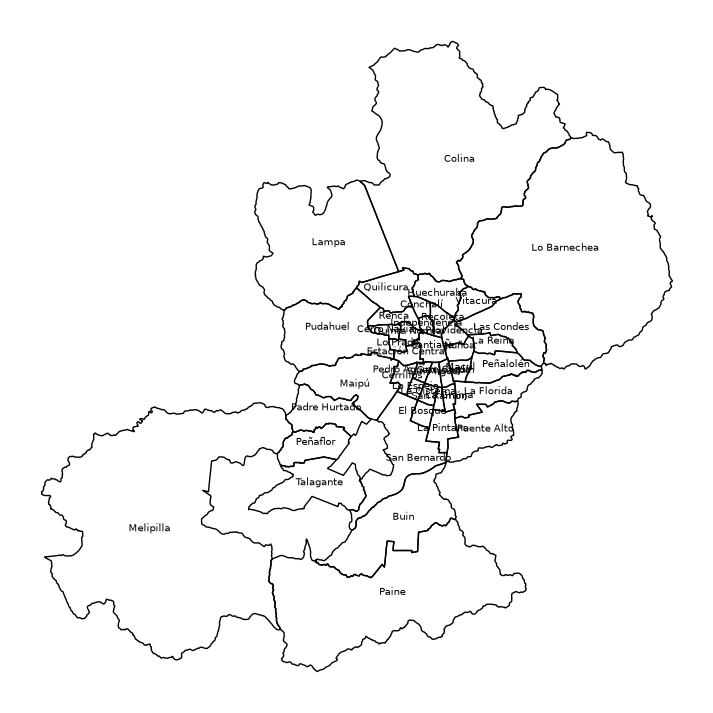

             comuna    area_km2                                                                                       display_name
         Las Condes   98.926007          Las Condes, Santiago, Provincia de Santiago, Santiago Metropolitan Region, 8320000, Chile
           Vitacura   28.293703            Vitacura, Santiago, Provincia de Santiago, Santiago Metropolitan Region, 8320000, Chile
        Providencia   14.438651                            Providencia, Provincia de Santiago, Santiago Metropolitan Region, Chile
              Ñuñoa   16.894206               Ñuñoa, Santiago, Provincia de Santiago, Santiago Metropolitan Region, 8320000, Chile
       Lo Barnechea 1022.262972        Lo Barnechea, Santiago, Provincia de Santiago, Santiago Metropolitan Region, 8320000, Chile
           La Reina   23.641334            La Reina, Santiago, Provincia de Santiago, Santiago Metropolitan Region, 8320000, Chile
           Santiago   23.143077                      Santiago, Provincia de Santiag

In [ ]:
if DEBUG:
    ax = limites.to_crs(CRS_METRICO).plot(figsize=(9, 9), edgecolor="black", facecolor="none")
    for _, r in limites.to_crs(CRS_METRICO).iterrows():
        p = r.geometry.representative_point()
        ax.annotate(r.comuna, (p.x, p.y), ha="center", fontsize=7)
    ax.set_axis_off()
    plt.show()
    print(limites[["comuna", "area_km2", "display_name"]].to_string(index=False))

### Dataset: una fila por comuna

In [ ]:
todos_tipos = [(c, t) for c, sub in categorias.items() for t in sub]
base = features if CONTAR_CON_BUFFER else features[features["dentro_comuna"]]

# Conteos comuna × tipo (incluye ceros)
conteos = (base.groupby(["comuna", "tipo"]).size()
           .unstack(fill_value=0)
           .reindex(index=limites["comuna"], columns=[t for _, t in todos_tipos], fill_value=0))

# Área de referencia para densidades
if CONTAR_CON_BUFFER and BUFFER_M > 0:
    area_ref = (limites.set_index("comuna").to_crs(CRS_METRICO).buffer(BUFFER_M).area / 1e6)
else:
    area_ref = limites.set_index("comuna")["area_km2"]

dataset = pd.DataFrame(index=limites["comuna"])
dataset["area_km2"] = limites.set_index("comuna")["area_km2"]

# n_<tipo>: conteo · dens_<tipo>: por km²
for _, t in todos_tipos:
    dataset[f"n_{t}"] = conteos[t]
for _, t in todos_tipos:
    dataset[f"dens_{t}"] = conteos[t] / area_ref

# Totales por categoría (útiles para un KNN con pocas variables)
for cat, sub in categorias.items():
    dataset[f"dens_cat_{cat}"] = conteos[list(sub)].sum(axis=1) / area_ref

# pct_area_<tipo>: % de la comuna cubierto (área recortada al límite)
area_tipo = (features[features["tipo"].isin(TIPOS_AREA)]
             .groupby(["comuna", "tipo"])["area_m2"].sum().unstack(fill_value=0)
             .reindex(index=dataset.index, columns=TIPOS_AREA, fill_value=0))
for t in TIPOS_AREA:
    dataset[f"pct_area_{t}"] = 100 * area_tipo[t] / (dataset["area_km2"] * 1e6)

# Por 10.000 habitantes (si existe el archivo de población)
if Path(ARCHIVO_POBLACION).exists():
    pob = pd.read_csv(ARCHIVO_POBLACION)
    pob["clave"] = pob["comuna"].map(slug)
    pob = pob.set_index("clave")["poblacion"]
    dataset["poblacion"] = dataset.index.map(lambda c: pob.get(slug(c), np.nan))
    dataset["hab_km2"] = dataset["poblacion"] / dataset["area_km2"]
    for _, t in todos_tipos:
        dataset[f"x10k_{t}"] = 1e4 * conteos[t] / dataset["poblacion"]
    for cat, sub in categorias.items():
        dataset[f"x10k_cat_{cat}"] = 1e4 * conteos[list(sub)].sum(axis=1) / dataset["poblacion"]
    faltan = dataset.index[dataset["poblacion"].isna()].tolist()
    if faltan:
        print("Sin población para:", faltan)
else:
    print(f"(No se encontró {ARCHIVO_POBLACION}: se omiten las variables por habitante)")

dataset = dataset.reset_index()
print(dataset.shape)
dataset.head()

(42, 125)


C:\Users\conta\AppData\Local\Temp\ipykernel_9084\2062856266.py:43: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"x10k_{t}"] = 1e4 * conteos[t] / dataset["poblacion"]
C:\Users\conta\AppData\Local\Temp\ipykernel_9084\2062856266.py:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"x10k_cat_{cat}"] = 1e4 * conteos[list(sub)].sum(axis=1) / dataset["poblacion"]
C:\Users\conta\AppData\Local\Temp\ipykernel_9084\2062856266.py:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of callin

,comuna,area_km2,n_Hospital,n_Clinica,n_Centro_salud,n_Consultorio,n_Farmacia,n_Parque,n_Mall,n_Restaurante,...,x10k_Bar_pub,x10k_Sitio_eriazo,x10k_Suelo_desnudo,x10k_cat_Salud,x10k_cat_Recreativo_Cultural,x10k_cat_Seguridad,x10k_cat_Educacion,x10k_cat_Comercio,x10k_cat_Transporte,x10k_cat_Negativos
0,Las Condes,98.926007,8,41,4,14,148,294,25,409,...,1.958573,1.114360,0.607833,7.260227,25.292604,0.303916,8.577198,13.473630,22.489819,5.200348
1,Vitacura,28.293703,3,17,2,4,54,142,15,233,...,3.702847,2.429993,2.198565,9.257116,46.517010,0.578570,9.372830,16.778523,28.697061,9.372830
2,Providencia,14.438651,14,48,6,24,155,133,12,614,...,10.488005,1.111312,0.486199,17.155875,56.676900,0.694570,15.905650,26.602025,30.352703,15.141623
3,Ñuñoa,16.894206,1,19,15,11,116,172,5,297,...,2.401985,0.662616,0.000000,6.708991,20.789590,0.579789,11.057412,11.347306,26.711725,5.590826
4,Lo Barnechea,1022.262972,0,7,5,2,25,129,10,77,...,0.887942,0.710353,1.420707,3.462973,19.623513,0.443971,5.682827,7.281122,20.067484,4.972474


### Unir ICVU (variable objetivo)

Desde la edición 2022, la CChC / Estudios Urbanos UC **ya no publica el puntaje numérico** del ICVU por comuna: solo cuatro niveles. Por eso la variable objetivo es el **nivel 2025 codificado como ordinal**: `ICVU_nivel` = 1 Bajo · 2 Medio bajo · 3 Medio alto · 4 Alto.

Si en algún momento consigues el puntaje numérico, basta con agregar una columna `ICVU` a `icvu_comunas.csv` y cambiar `OBJETIVO = "ICVU"` en el notebook del modelo.

In [ ]:
CODIGO_NIVEL = {"Bajo": 1, "Medio bajo": 2, "Medio alto": 3, "Alto": 4}

if Path(ARCHIVO_ICVU).exists():
    icvu = pd.read_csv(ARCHIVO_ICVU)
else:   # se construye desde el diccionario de parámetros
    icvu = pd.DataFrame({"comuna": list(NIVEL_ICVU_2025), "nivel_2025": list(NIVEL_ICVU_2025.values())})
    icvu["ICVU_nivel"] = icvu["nivel_2025"].map(CODIGO_NIVEL)
    icvu.to_csv(ARCHIVO_ICVU, index=False)

icvu["clave"] = icvu["comuna"].map(slug)
dataset["clave"] = dataset["comuna"].map(slug)
repetidas = [c for c in icvu.columns if c not in ("comuna", "clave") and c in dataset.columns]
dataset = (dataset.drop(columns=repetidas)   # permite re-ejecutar la celda
           .merge(icvu.drop(columns="comuna"), on="clave", how="left").drop(columns="clave"))
objetivo = "ICVU" if "ICVU" in dataset.columns else "ICVU_nivel"
faltan = dataset.loc[dataset[objetivo].isna(), "comuna"].tolist()
print(f"Objetivo unido ({objetivo}). Comunas sin dato: {faltan if faltan else 'ninguna'}")

Objetivo unido (ICVU_nivel). Comunas sin dato: ninguna


C:\Users\conta\AppData\Local\Temp\ipykernel_9084\1214441515.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset["clave"] = dataset["comuna"].map(slug)


### Guardado

In [ ]:
features.to_file(SALIDA_GPKG, layer="features", driver="GPKG")
limites.to_file(SALIDA_GPKG, layer="limites", driver="GPKG")
features.drop(columns="geometry").to_csv(SALIDA_CSV, index=False)

resumen = (base.groupby(["comuna", "categoria", "tipo"]).size().rename("n")
           .reindex(pd.MultiIndex.from_tuples(
               [(co, c, t) for co in limites["comuna"] for c, t in todos_tipos],
               names=["comuna", "categoria", "tipo"]), fill_value=0)
           .reset_index())
resumen.to_csv(SALIDA_RESUMEN, index=False)
dataset.to_csv(SALIDA_DATASET, index=False)

log("Guardado:", SALIDA_GPKG, SALIDA_CSV, SALIDA_RESUMEN, SALIDA_DATASET)
if DEBUG:
    print(resumen.pivot_table(index="tipo", columns="comuna", values="n").to_string())

Guardado: features_comunas.gpkg features_comunas.csv resumen_conteos.csv dataset_comunas.csv
comuna                Buin  Cerrillos  Cerro Navia  Colina  Conchalí  El Bosque  Estación Central  Huechuraba  Independencia  La Cisterna  La Florida  La Granja  La Pintana  La Reina  Lampa  Las Condes  Lo Barnechea  Lo Espejo  Lo Prado  Macul   Maipú  Melipilla  Padre Hurtado  Paine  Pedro Aguirre Cerda  Peñaflor  Peñalolén  Providencia  Pudahuel  Puente Alto  Quilicura  Quinta Normal  Recoleta  Renca  San Bernardo  San Joaquín  San Miguel  San Ramón  Santiago  Talagante  Vitacura  Ñuñoa
tipo                                                                                                                                                                                                                                                                                                                                                                                                                         